# Train EDA and cleaning (Colab-ready)

Cleans the Cat Image Arena training responses and runs the first-pass exploratory checks.

- **Input:** `train.csv` (24,896 rows)
- **Output:** `prepared/cleaned_training_responses.csv`
- **Images:** optional — path existence checks run only if a photos folder is present

**What this notebook is for:** turn the raw training file into a trustworthy analysis table, then answer basic questions about coverage, choice balance, respondent background, and simple agreement patterns.

A row is one response to a pair of photos. `choice` is A or B. Background columns describe the respondent; there is no respondent id.

**Course / report link:** This notebook supplies the cleaned training matrix required by the midterm report’s *Data understanding and preparation* section. The derived columns (`chose_a`, `demo_complete`, ordered/unordered pair ids) are the starting point for logistic regression, Bradley–Terry ranking models, and tree ensembles in later notebooks (Chapters 3–7).

**Bottom line of the whole notebook:** the training file is clean and consistent; keep all 24,896 rows; missing background is an all-or-nothing block of 508 rows; there is a mild side-A preference (~52%); and for between-cat pairs, agreement rises when the two cats differ more in win rate — a first hint that preferences are not pure noise.


## 0. Setup (Colab or local)

**Purpose:** configure paths, create output folders, and define shared constants.

**What this section does:**
- Locates `train.csv` (or `training-responses.csv`) in common places (cwd, Colab `/content`, Drive)
- Optionally finds a photos/images folder for later file checks
- Defines the six background fields (`DEMO_COLS`) and the allowed value sets (`ALLOWED`) used in validation

**How to read the output:** you should see `TRAIN_PATH` pointing at your CSV. `IMAGE_ROOT` may say “not found”; that only skips file-existence checks — cleaning and EDA still run.

**Bottom line:** if this cell errors with “Could not find train.csv”, upload the file (optional cell below) or fix the working directory before continuing.


In [ ]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)

# --- paths ---
# In Colab: upload train.csv (or mount Drive) then set DATA_DIR if needed.
# Default: current working directory, or a folder that already contains train.csv.

def find_data_dir() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd() / "artifacts",
        Path.cwd() / "cat-arena",
        Path("/content"),
        Path("/content/drive/MyDrive"),
    ]
    for base in candidates:
        for name in ("train.csv", "training-responses.csv"):
            if (base / name).is_file():
                return base
            if (base / "cat-arena" / name).is_file():
                return base / "cat-arena"
    return Path.cwd()

DATA_DIR = find_data_dir()
TRAIN_CANDIDATES = [
    DATA_DIR / "train.csv",
    DATA_DIR / "training-responses.csv",
    DATA_DIR / "cat-arena" / "training-responses.csv",
]
TRAIN_PATH = next((p for p in TRAIN_CANDIDATES if p.is_file()), None)
if TRAIN_PATH is None:
    raise FileNotFoundError(
        "Could not find train.csv or training-responses.csv. "
        "Upload the file to the working directory (or set DATA_DIR)."
    )

IMAGE_ROOT_CANDIDATES = [
    DATA_DIR / "photos",
    DATA_DIR / "images",
    DATA_DIR / "cat-arena" / "photos",
    DATA_DIR.parent / "cat-arena" / "photos",
]
IMAGE_ROOT = next((p for p in IMAGE_ROOT_CANDIDATES if p.is_dir()), None)

OUT_DIR = Path.cwd() / "prepared"
FIG_DIR = Path.cwd() / "model-checks" / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

DEMO_COLS = [
    "gender",
    "pet_history",
    "pet_care",
    "pet_contact",
    "future_pet",
    "mbti_ie",
]

ALLOWED = {
    "choice": {"A", "B"},
    "comparison_type": {"within_cat", "between_cats"},
    "gender": {"man", "woman"},
    "pet_history": {"current", "past", "never"},
    "pet_care": {"never", "occasionally", "past_regular", "current_regular"},
    "pet_contact": {"never", "rarely", "sometimes", "often", "daily"},
    "future_pet": {"yes", "no", "unsure"},
    "mbti_ie": {"I", "E", "unknown"},
}

pd.set_option("display.max_columns", 40)
print("TRAIN_PATH:", TRAIN_PATH)
print("IMAGE_ROOT:", IMAGE_ROOT if IMAGE_ROOT else "(not found — image file checks will be skipped)")
print("OUT_DIR:", OUT_DIR.resolve())
print("FIG_DIR:", FIG_DIR.resolve())

TRAIN_PATH: /content/train.csv
IMAGE_ROOT: (not found — image file checks will be skipped)
OUT_DIR: /content/prepared
FIG_DIR: /content/model-checks/figures


### Optional: upload `train.csv` in Colab

**When to use this:** only if `train.csv` is not already visible in the runtime file browser.

Uncomment the code in the next cell, run it, and choose `train.csv` from your computer.

**Bottom line:** skip this section entirely when the setup cell already printed a valid `TRAIN_PATH`.


In [ ]:
# Uncomment in Google Colab if you need to upload the file interactively.
# from google.colab import files
# uploaded = files.upload()  # select train.csv
# if "train.csv" in uploaded:
#     TRAIN_PATH = Path("train.csv")
#     print("Using uploaded train.csv")

## 1. Load

**This section answers:** *Can we read the raw training file cleanly?*

**What it does:**
- Reads the CSV with `utf-8-sig` so a BOM on `train_row_id` is stripped
- Forces all columns to string and keeps blanks as empty strings (not NaN), so missingness can be inspected honestly

**Why it matters:** a BOM or early NaN conversion can create fake “new” column names or hide which fields were actually blank.

**How to read the result:** expect **24,896 rows** and **13 columns**:  
`train_row_id`, `a_cat`, `b_cat`, `a_image`, `b_image`, `choice`, `comparison_type`, plus the six background fields. The head preview should show real cat ids and paths like `cat_002145/cat_002145_0006.jpg`.

**Bottom line:** if the row count is not 24,896 or a column name looks mangled (e.g. with a BOM character), stop and fix the file path / encoding before cleaning.


In [ ]:
raw = pd.read_csv(TRAIN_PATH, encoding="utf-8-sig", dtype=str, keep_default_na=False)
print(f"{len(raw):,} rows, {raw.shape[1]} columns")
print("columns:", list(raw.columns))
raw.head()

24,896 rows, 13 columns
columns: ['train_row_id', 'a_cat', 'b_cat', 'a_image', 'b_image', 'choice', 'comparison_type', 'gender', 'pet_history', 'pet_care', 'pet_contact', 'future_pet', 'mbti_ie']


,train_row_id,a_cat,b_cat,a_image,b_image,choice,comparison_type,gender,pet_history,pet_care,pet_contact,future_pet,mbti_ie
0,TR000001,cat_002145,cat_002145,cat_002145/cat_002145_0006.jpg,cat_002145/cat_002145_0003.jpg,A,within_cat,woman,current,current_regular,sometimes,yes,I
1,TR000002,cat_000751,cat_005017,cat_000751/cat_000751_0005.jpg,cat_005017/cat_005017_0001.jpg,A,between_cats,man,never,never,rarely,yes,I
2,TR000003,cat_001019,cat_001019,cat_001019/cat_001019_0002.jpg,cat_001019/cat_001019_0005.jpg,A,within_cat,man,current,occasionally,rarely,unsure,I
3,TR000004,cat_000406,cat_001177,cat_000406/cat_000406_0004.jpg,cat_001177/cat_001177_0004.jpg,A,between_cats,woman,current,current_regular,daily,yes,I
4,TR000005,cat_000361,cat_000360,cat_000361/cat_000361_0005.jpg,cat_000360/cat_000360_0001.jpg,B,between_cats,man,never,occasionally,rarely,unsure,I


## 2. Missing values

**This section answers:** *Which fields are blank, and do blanks cluster on the same rows?*

**What this analysis is testing:** whether background information is missing at random field-by-field, or only in whole blocks.

**How to read the result:**
- Each of the six background fields shows **508 blank rows**
- “All 6 background fields blank” = **508**
- “Some but not all blank” = **0**

So missingness is all-or-nothing: a respondent either filled the whole background block or none of it. Core fields (`choice`, cats, images, comparison type) are never blank in this file.

**Bottom line:** treat background missingness as a single indicator (later: `demo_complete`), not as six independent holes. Do **not** drop these 508 rows yet — they still have valid choices.


In [ ]:
blank_counts = (raw == "").sum()
blank_counts = blank_counts[blank_counts > 0]
display(blank_counts.to_frame("blank rows"))

n_blank = (raw[DEMO_COLS] == "").sum(axis=1)
print("all 6 background fields blank:", int((n_blank == 6).sum()))
print("some but not all blank:", int(((n_blank > 0) & (n_blank < 6)).sum()))
raw.loc[n_blank == 6, ["train_row_id", "choice", "comparison_type", *DEMO_COLS]].head()

,blank rows
gender,508
pet_history,508
pet_care,508
pet_contact,508
future_pet,508
mbti_ie,508


all 6 background fields blank: 508
some but not all blank: 0


,train_row_id,choice,comparison_type,gender,pet_history,pet_care,pet_contact,future_pet,mbti_ie
26,TR000027,A,between_cats,,,,,,
62,TR000063,A,between_cats,,,,,,
84,TR000085,A,between_cats,,,,,,
87,TR000088,B,between_cats,,,,,,
118,TR000119,B,between_cats,,,,,,


## 3. Cleaning

**Purpose:** build the analysis table without dropping training rows.

**What this section does:**
- Turns all-blank background fields into missing (`pd.NA`); **keeps the 508 rows**
- Adds `demo_complete` so later plots can restrict to rows with background data
- Adds `chose_a` (1 if choice is A)
- Adds `ordered_pair_id` (paths in the order shown) and `unordered_pair_id` (sorted paths, so left/right swaps share an id)

**How to read the result:**  
`demo_complete: 24,388` and `missing background: 508`. Those two numbers must add to 24,896.

**Why keep blank-background rows:** they still have a valid choice and pair. Notebook 2 shows they choose A more often (~60% vs ~52%), so excluding them would bias overall rates.

**Bottom line:** cleaning here means *standardize and flag*, not *delete*. The analysis table stays the same length as the raw file.


In [ ]:
train = raw.copy()
train[DEMO_COLS] = train[DEMO_COLS].replace("", pd.NA)
train["demo_complete"] = train[DEMO_COLS].notna().all(axis=1)
train["chose_a"] = (train["choice"] == "A").astype(int)
train["ordered_pair_id"] = train["a_image"] + "||" + train["b_image"]
train["unordered_pair_id"] = [
    "||".join(sorted(pair))
    for pair in zip(train["a_image"], train["b_image"])
]

print(
    f"demo_complete: {int(train['demo_complete'].sum()):,}  "
    f"missing background: {int((~train['demo_complete']).sum()):,}"
)

demo_complete: 24,388  missing background: 508


## 4. Validation

**This section answers:** *Is the cleaned table internally consistent enough to trust?*

**What this analysis is testing:**
- Unique `train_row_id`
- Only allowed labels in choice, comparison type, and background fields
- `comparison_type` matches whether `a_cat` and `b_cat` are the same
- No identical image on both sides; paths sit under the stated cat id
- If a photos folder exists, every referenced image file is present

**How to read the result:** every check should print `ok` or `0` problems. You should see **24,896 unique ids**, **1,296 images referenced**, and either `missing files: 0` or `skipped (no IMAGE_ROOT)`.

**Bottom line:** if this cell raises a `ValueError`, the raw file has a structural problem (bad label, mismatched comparison type, etc.). Do not write or use a cleaned CSV until it passes. After a clean run, `prepared/cleaned_training_responses.csv` is safe for notebook 2 and modeling.


In [ ]:
def validate(train: pd.DataFrame, image_root) -> None:
    if not train["train_row_id"].is_unique:
        raise ValueError("train_row_id is not unique")
    print("unique ids:", True, train["train_row_id"].nunique())

    for col, allowed in ALLOWED.items():
        unexpected = set(train[col].dropna().unique()) - allowed
        if unexpected:
            raise ValueError(f"{col}: unexpected values {sorted(unexpected)}")
        print(col, "ok")

    same_cat = train["a_cat"] == train["b_cat"]
    type_ok = ((train["comparison_type"] == "within_cat") & same_cat) | (
        (train["comparison_type"] == "between_cats") & ~same_cat
    )
    n_mismatch = int((~type_ok).sum())
    if n_mismatch:
        raise ValueError(f"comparison_type mismatches: {n_mismatch}")
    print("comparison_type mismatches:", 0)

    n_same_image = int((train["a_image"] == train["b_image"]).sum())
    if n_same_image:
        raise ValueError(f"same image on both sides: {n_same_image}")
    print("same image on both sides:", 0)

    bad_paths = 0
    for side in ("a", "b"):
        for cat, path in zip(train[f"{side}_cat"], train[f"{side}_image"]):
            if not (path.startswith(cat + "/") and path.endswith(".jpg")):
                bad_paths += 1
    if bad_paths:
        raise ValueError(f"paths that don't sit under the cat id: {bad_paths}")
    print("paths that don't sit under the cat id:", 0)

    referenced = set(train["a_image"]) | set(train["b_image"])
    print("images referenced:", len(referenced))
    if image_root is not None:
        missing_files = [p for p in sorted(referenced) if not (image_root / p).is_file()]
        if missing_files:
            raise ValueError(f"missing image files: {len(missing_files)} (e.g. {missing_files[:3]})")
        print("missing files:", 0)
    else:
        print("missing files: skipped (no IMAGE_ROOT)")


validate(train, IMAGE_ROOT)

unique ids: True 24896
choice ok
comparison_type ok
gender ok
pet_history ok
pet_care ok
pet_contact ok
future_pet ok
mbti_ie ok
comparison_type mismatches: 0
same image on both sides: 0
paths that don't sit under the cat id: 0
images referenced: 1296
missing files: skipped (no IMAGE_ROOT)


In [ ]:
cleaned_path = OUT_DIR / "cleaned_training_responses.csv"
train.to_csv(cleaned_path, index=False)
print("wrote", cleaned_path.resolve(), len(train), "rows")

wrote /content/prepared/cleaned_training_responses.csv 24896 rows


## 5. Coverage

**This section answers:** *How much of the cat/image world does the training set actually use?*

**What it reports:** counts of unique cats and images, split of within-cat vs between-cat rows, and (if photos are on disk) how many files never appear in train.

**How to read the result (this dataset):**
- **237 unique cats**, **1,296 unique images** in train
- **3,003 within-cat** rows (~12%) vs **21,893 between-cats** rows (~88%)
- Training is dominated by comparisons *across* different cats; same-cat photo pairs are a minority

If a photos folder is present, many jpgs on disk may never appear in train (test uses other photos). That is expected, not an error.

**Bottom line:** later win rates and reliability speak for these 237 cats / 1,296 images. Between-cat signal will drive most of the story; within-cat is a smaller, harder subset.


In [ ]:
n_cats = pd.unique(train[["a_cat", "b_cat"]].values.ravel()).size
n_images = len(set(train["a_image"]) | set(train["b_image"]))
print(f"unique cats in train: {n_cats:,}")
print(f"unique images in train: {n_images:,}")
print(f"within_cat rows: {(train['comparison_type'] == 'within_cat').sum():,}")
print(f"between_cats rows: {(train['comparison_type'] == 'between_cats').sum():,}")

if IMAGE_ROOT is not None:
    disk_images = {p.relative_to(IMAGE_ROOT).as_posix() for p in IMAGE_ROOT.glob("cat_*/*.jpg")}
    referenced = set(train["a_image"]) | set(train["b_image"])
    print(f"jpgs on disk: {len(disk_images):,}")
    print(f"on disk but never in train: {len(disk_images - referenced):,}")
    print(f"in train but missing on disk: {len(referenced - disk_images):,}")
else:
    print("(skip disk coverage — no photos folder)")

unique cats in train: 237
unique images in train: 1,296
within_cat rows: 3,003
between_cats rows: 21,893
(skip disk coverage — no photos folder)


## 6. How often a cat or a photo is shown

**This section answers:** *Are some cats or photos over-represented?*

**What this analysis is testing:** the balance of exposure. Highly uneven appearance counts can make a few cats or images dominate win rates and agreement stats.

**How to read the result (this dataset):**
- **Per cat:** median about **212** appearances, max about **245** — fairly even across cats
- **Per image:** median about **39**, max about **73** — more spread, but no extreme single-image monopoly
- Histograms should look unimodal without a huge right tail

**Bottom line:** exposure is balanced enough that overall cat win rates are not artifacts of one cat being shown vastly more often. Image-level counts vary more, which is one reason image reliability (notebook 2) is weaker than cat reliability.


appearances per cat — median 212 max 245
appearances per image — median 39 max 73


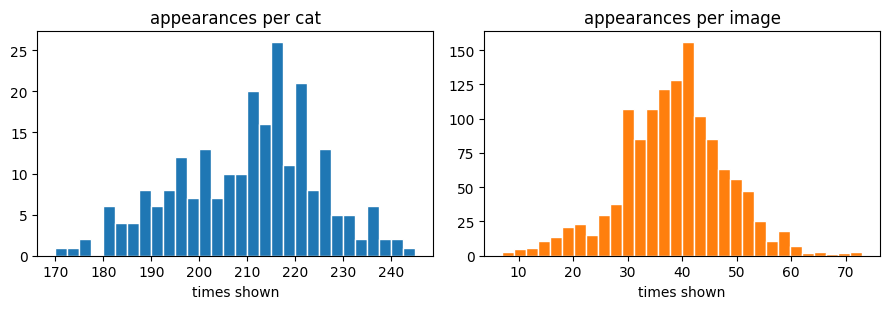

In [ ]:
shown = pd.concat(
    [
        train[["a_cat", "a_image"]].rename(columns={"a_cat": "cat", "a_image": "image"}),
        train[["b_cat", "b_image"]].rename(columns={"b_cat": "cat", "b_image": "image"}),
    ],
    ignore_index=True,
)

cat_n = shown.groupby("cat").size()
img_n = shown.groupby("image").size()

print("appearances per cat — median", int(cat_n.median()), "max", int(cat_n.max()))
print("appearances per image — median", int(img_n.median()), "max", int(img_n.max()))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(cat_n, bins=30, color="C0", edgecolor="white")
axes[0].set_title("appearances per cat")
axes[0].set_xlabel("times shown")
axes[1].hist(img_n, bins=30, color="C1", edgecolor="white")
axes[1].set_title("appearances per image")
axes[1].set_xlabel("times shown")
fig.tight_layout()
fig.savefig(FIG_DIR / "appearances_hist.png", bbox_inches="tight")
plt.show()

## 7. Choice

**This section answers:** *Is there a side bias toward A or B?*

**What this analysis is testing:** the overall share choosing A, and whether that share differs for within-cat vs between-cat comparisons.

**How to read the result (this dataset):**
- **A: 12,921 (51.9%)** vs **B: 11,975 (48.1%)**
- Between-cats share A ≈ **0.520**; within-cat ≈ **0.514** — almost the same

So there is a small but real preference for the left/side-A slot, and it is not driven by only one comparison type.

**Bottom line:** any predictive model should beat a naive “always A” baseline of ~52%, not 50%. Side bias is mild; the interesting signal is in *which* cat or photo wins, not in a strong left/right rule.


In [ ]:
choice_counts = train["choice"].value_counts().rename("responses")
choice_share = (choice_counts / choice_counts.sum()).rename("share")
display(pd.concat([choice_counts, choice_share], axis=1).round(4))

by_type = (
    train.groupby("comparison_type")["chose_a"]
    .agg(n="size", share_a="mean")
    .round(4)
)
display(by_type)

print(f"overall P(choose A) = {train['chose_a'].mean():.4f}")

,responses,share
choice,,
A,12921,0.519
B,11975,0.481


,n,share_a
comparison_type,,
between_cats,21893,0.5197
within_cat,3003,0.5142


overall P(choose A) = 0.5190


## 8. Background

**This section answers:** *Who is in the sample, among rows with complete background data?*

**What it does:**
- Frequency tables for gender, pet history/care/contact, future pet intent, and MBTI I/E
- Top combined “profiles” (full combinations of the six fields)

**How to read the result (this dataset, n = 24,388 complete rows):**
- **Gender:** more men (~57%) than women (~43%)
- **Pet history:** never ~38%, current ~36%, past ~26%
- **Future pet:** strong lean to **yes** (~70%)
- **MBTI I/E:** I ~57%, E ~26%, unknown ~17%
- About **69 unique full profiles**; the single most common is roughly “man | never | never | rarely | yes | I” (on the order of 1,600 rows)

Background fields are correlated with each other (e.g. pet history and pet care) — notebook 2 quantifies that with Cramér’s V. Association of background *with choice* is weak there.

**Bottom line:** the sample is not uniform, but background composition is secondary for predicting A vs B. Use `demo_complete` when studying respondents; use all rows when studying overall choice rates.


In [ ]:
complete = train[train["demo_complete"]].copy()
print(f"complete background rows: {len(complete):,}")

for col in DEMO_COLS:
    vc = complete[col].value_counts(dropna=False)
    share = (vc / len(complete)).round(3)
    print(f"\n{col}")
    display(pd.DataFrame({"n": vc, "share": share}))

complete background rows: 24,388

gender


,n,share
gender,,
man,13998,0.574
woman,10390,0.426



pet_history


,n,share
pet_history,,
never,9315,0.382
current,8650,0.355
past,6423,0.263



pet_care


...

,n,share
pet_contact,,
rarely,7566,0.310
sometimes,5793,0.238
daily,5084,0.208
often,4891,0.201
never,1054,0.043



future_pet


,n,share
future_pet,,
yes,17172,0.704
unsure,4834,0.198
no,2382,0.098



mbti_ie


,n,share
mbti_ie,,
I,14000,0.574
E,6346,0.260
unknown,4042,0.166


In [ ]:
profile = complete[DEMO_COLS].astype(str).agg(" | ".join, axis=1)
top_profiles = profile.value_counts().head(15).rename("n")
display(top_profiles.to_frame())
print("unique full profiles:", profile.nunique())

,n
man | never | never | rarely | yes | I,1600
woman | never | never | rarely | yes | I,1070
woman | current | current_regular | daily | yes | I,948
man | never | never | never | yes | unknown,646
man | current | occasionally | sometimes | yes | I,645
man | current | occasionally | often | yes | I,629
man | past | past_regular | sometimes | yes | I,627
man | past | past_regular | daily | yes | I,501
man | current | past_regular | often | yes | I,498
man | never | never | rarely | unsure | E,412


unique full profiles: 69


## 9. Repeated pairs

**This section answers:** *How often is the same ordered pair answered more than once?*

**What this analysis is testing:** whether the data support agreement and reliability checks. Pairs seen twice (same left/right order) are the basis for “do two responses match?” in the next section and in notebook 2.

**How to read the result (this dataset):**
- **5,430** ordered pairs appear **once**; **9,733** appear **exactly twice**
- **15,163** unique ordered pairs; **8,049** unique unordered pairs

So a large fraction of the design is duplicated in the same layout — enough to measure agreement. Unordered count is lower because many pairs also appear with A/B swapped.

**Bottom line:** repeated ordered pairs are common enough for a serious agreement analysis. Notebook 2’s κ and swap tests are built on this structure, not on thin one-off pairs.


In [ ]:
multiplicity = train.groupby("ordered_pair_id").size()
print("ordered pairs by response count:")
display(multiplicity.value_counts().sort_index().rename("n_pairs").to_frame())

n_unordered = train["unordered_pair_id"].nunique()
n_ordered = train["ordered_pair_id"].nunique()
print(f"unique ordered pairs: {n_ordered:,}")
print(f"unique unordered pairs: {n_unordered:,}")

ordered pairs by response count:


,n_pairs
1,5430
2,9733


unique ordered pairs: 15,163
unique unordered pairs: 8,049


## 10. Agreement and how far apart the cats are

**This section answers an important question:** *When the same between-cat pair is answered twice, do the two responses agree more often if the two cats have very different overall win rates?*

**What this analysis is testing:** a simple signal check — if people are responding to cat quality, agreement should rise as the win-rate gap between the two cats grows.

**Scope:** between-cat pairs only, same ordered layout, answered exactly twice. Formal Cohen’s κ, swap effects, and split-half reliability are in **notebook 2**.

**How to read the result (this dataset):**
- About **8,750** repeated between-cat ordered pairs
- Overall both responses match ≈ **0.561** (only a bit above 50%)
- By win-rate gap (quintiles), match rate rises roughly:

| Win-rate gap (approx.) | Both match |
| ---------------------- | ---------- |
| 0.00 – 0.03            | ~0.51      |
| 0.03 – 0.06            | ~0.53      |
| 0.06 – 0.10            | ~0.55      |
| 0.10 – 0.16            | ~0.57      |
| 0.16 – 0.50            | ~0.65      |

The gray horizontal line on the chart is the overall mean (~0.56). The bar for the largest gap sits clearly above it.

**Bottom line:** raw agreement is weak (people often disagree on the same pair), but it systematically improves when one cat is much stronger than the other. That is early evidence of a real preference signal concentrated in *which cat* — consistent with notebook 2’s finding that cat-level reliability is much higher than within-cat image reliability.


,win_rate_gap,pairs,both_match
0,0.00 to 0.03,1751,0.512
1,0.03 to 0.06,1749,0.533
2,0.06 to 0.10,1751,0.547
3,0.10 to 0.16,1749,0.567
4,0.16 to 0.50,1750,0.647


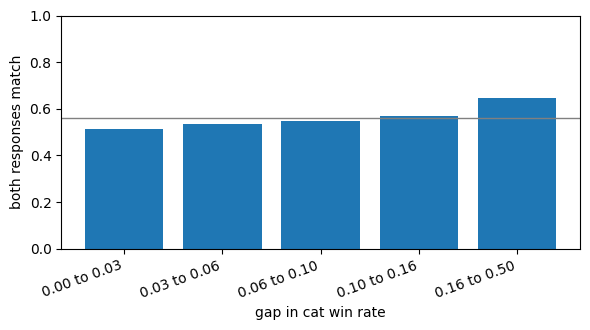

repeated between-cat pairs: both match 0.561, n = 8,750


In [ ]:
between = train[train["comparison_type"] == "between_cats"]
wins = pd.concat(
    [
        between[["a_cat", "chose_a"]]
        .rename(columns={"a_cat": "cat"})
        .assign(won=between["chose_a"].to_numpy()),
        between[["b_cat", "chose_a"]]
        .rename(columns={"b_cat": "cat"})
        .assign(won=1 - between["chose_a"].to_numpy()),
    ],
    ignore_index=True,
)
cat_win_rate = wins.groupby("cat")["won"].mean()

n_resp = between.groupby("ordered_pair_id").size()
twice = between[between["ordered_pair_id"].isin(n_resp[n_resp == 2].index)]
agree = twice.groupby("ordered_pair_id")["choice"].nunique().eq(1)
meta = twice.groupby("ordered_pair_id").agg(
    a_cat=("a_cat", "first"),
    b_cat=("b_cat", "first"),
)
meta["gap"] = (meta["a_cat"].map(cat_win_rate) - meta["b_cat"].map(cat_win_rate)).abs()
meta["agree"] = agree
meta["gap_bin"] = pd.qcut(meta["gap"], 5)

by_gap = (
    meta.groupby("gap_bin", observed=True)["agree"]
    .agg(pairs="size", both_match="mean")
    .reset_index()
)
by_gap["win_rate_gap"] = by_gap["gap_bin"].map(
    lambda iv: f"{max(iv.left, 0):.2f} to {iv.right:.2f}"
)
display(by_gap[["win_rate_gap", "pairs", "both_match"]].round(3))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(range(len(by_gap)), by_gap["both_match"], color="C0")
ax.set_xticks(range(len(by_gap)), by_gap["win_rate_gap"], rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("both responses match")
ax.set_xlabel("gap in cat win rate")
ax.axhline(meta["agree"].mean(), color="0.5", lw=1)
fig.tight_layout()
fig.savefig(FIG_DIR / "agreement_by_win_gap.png", bbox_inches="tight")
plt.show()
print(
    f"repeated between-cat pairs: both match {meta['agree'].mean():.3f}, "
    f"n = {len(meta):,}"
)

## 11. What changed

**Purpose:** one-page audit of cleaning decisions so the next person does not have to re-read the whole notebook.

**Summary of decisions:**
- BOM stripped on read
- 508 all-blank background rows **kept**; those fields are missing and `demo_complete` is false
- Ids, labels, path shape, and (if available) image files checked out
- Cleaned table has the same 24,896 rows plus derived columns
- Extra images on disk that train never uses stay in the photos folder (when present)

**How to read the summary cell:** confirm rows = 24,896, demo_complete = 24,388, missing background = 508, P(choose A) ≈ 0.519, and that the cleaned file path exists.

**Bottom line (notebook 1 overall):**
1. **Data quality:** structurally clean; safe to analyze after this pipeline.
2. **Missing background:** 508 all-or-nothing rows — flag with `demo_complete`, do not drop for overall rates.
3. **Design:** mostly between-cat (~88%); 237 cats, 1,296 images; many pairs repeated twice.
4. **Signal preview:** mild side-A bias (~52%); agreement is modest overall but rises with cat win-rate gap — preferences are noisy but not random, and cat identity is the plausible carrier of signal.

Downstream association and reliability analysis should start from `prepared/cleaned_training_responses.csv` (notebook 2).


## Course / report use of this cleaned table

- Keep **all 24,896 rows** for overall rates and for image/cat strength estimation.
- Use the `demo_complete` flag to restrict demographic models (logistic regression, random forests) to the 24,388 rows with background.
- The ordered- and unordered-pair ids support agreement checks and proper train/validation splits that avoid leaking the same pair (or both orientations of a pair) into both folds — a point the midterm guidelines explicitly ask you to discuss.
- Next steps in the course pipeline: agreement & reliability (notebook 2), demographic preference tables (notebook 3), then preference models (logistic / Bradley–Terry / forests).


In [ ]:
print("Summary")
print(f"  rows:              {len(train):,}")
print(f"  demo_complete:     {int(train['demo_complete'].sum()):,}")
print(f"  missing background:{int((~train['demo_complete']).sum()):,}")
print(f"  P(choose A):       {train['chose_a'].mean():.4f}")
print(f"  cleaned file:      {cleaned_path.resolve()}")
print(f"  figures:           {FIG_DIR.resolve()}")

Summary
  rows:              24,896
  demo_complete:     24,388
  missing background:508
  P(choose A):       0.5190
  cleaned file:      /content/prepared/cleaned_training_responses.csv
  figures:           /content/model-checks/figures
